# 1. Combining Modules into the BCR–TLR–NF-κB Tri-Model

In Tutorial 3, you ran the standalone published **NF-κB module** (101 species, 257 parameters) by feeding a hand-defined `ikk1_ikkactivity(t)` curve directly into the network.

That setup is great when you already know what active IKK looks like over time. In real B-cell lymphomas, however, mutations often sit **upstream of IKK** — in the B-cell receptor (**BCR** / `CD79B`), the Toll-like receptor (**TLR** / `MYD88`), or the kinase hub **TAK1**. To study how those upstream mutations alter NF-κB signalling (as in **Figure 5 of Jayawant *et al.***, [`SiFTW/NFkBModel/Figure5`](https://github.com/SiFTW/NFkBModel/tree/main/Figure5)), we need a model that includes those upstream receptor pathways.

Rather than maintaining one monolithic 500-reaction spreadsheet, we keep each biological pathway in its own folder (`BCR`, `TLR`, `NFkB`) and connect them with a **`linking`** adapter module.

:::{tip} Start your live Julia kernel
Click **Activate Live Editable Julia Cells** near the top of the page, then run each cell in order with **Shift + Enter**.
:::

---

## How Modular Combination Works

```{figure} ../images/tri-model-modules.svg
:alt: Architecture of the Figure 5 Tri-Model showing BCR, TLR, linking, and NF-kB CSV modules combining into 150 species and 444 parameters
:width: 100%

The four CSV folders in `NFkB_Figure5/moduleDefinitionFiles/`. Upstream active IKK pools from the **BCR** and **TLR** modules converge inside the **`linking`** module into a single `totalActiveIKK` species, which drives IκB degradation inside the **NF-κB** module.
```

The helper script `combineModels.jl` merges the four folders in three steps:

1. **Load the `linking` module first.** Its reactions define how upstream active IKK pools (`IKKp`, `IKKpC`, `IKKpp`, `IKKppC` from BCR, and `IKK_on` from TLR) combine into `totalActiveIKK` via the rate law `sumThings`, and how `totalActiveIKK` drives IκBα/β/ε degradation.
2. **Automatically remove replaced reactions.** As `combineModels` reads `BCR`, `TLR`, and `NFkB`, it checks whether any reaction has the same `Substrate` and `Products` pair as a reaction already present in `linking`. When it finds one — such as the old standalone `IkBa -> ` or `RelAp50IkBa -> RelAp50` reactions that used `ikk1_ikkactivity(t)` — it drops the old version so the reaction is not double-counted.
3. **Append a module suffix to every parameter name.** Because two different modules might independently define a parameter with the same name, `combineModels` appends `-BCR`, `-TLR`, `-NFkB`, or `-linking` to every parameter name in both `reactions.csv` and `parameters.csv`.
   - For example, `k1_RelASynth` becomes **`k1_RelASynth-NFkB`**, `k1_MYD88SELFACTIVATION` becomes **`k1_MYD88SELFACTIVATION-TLR`**, and `k1_Tp0` becomes **`k1_Tp0-BCR`**.
   - Notice this still follows the `CSV2Julia` underscore rule from Tutorial 3: everything **before the first `_`** (`k1`) is untouched!

---

## Step 1: Inspect the `linking` Module & Combine All Four Modules

Let's inspect the `linking` module CSVs, run `combineModels(["BCR", "TLR", "NFkB"])`, and pass the combined tables to `CSV2Julia` (`csv2model-multiscale.py`) in **`param` mode**.

In [1]:
using DifferentialEquations
using Plots
using CSV
using DataFrames

gr()

# Point to the exact Figure 5 module files from SiFTW/NFkBModel/Figure5
moduleDefinitionFilesFolder = "NFkB_Figure5/moduleDefinitionFiles/"
delay = false

println("Sample reactions in the linking module:")
link_rxns = CSV.read(moduleDefinitionFilesFolder * "linking/reactions.csv", DataFrame; stripwhitespace=true)
display(first(link_rxns, 6))

println("\nRate laws in the linking module:")
display(CSV.read(moduleDefinitionFilesFolder * "linking/rateLaws.csv", DataFrame; stripwhitespace=true))

# Merge BCR, TLR, NFkB, and linking into combinedModelDefinitionFiles/
include("NFkB_Figure5/combineModels.jl")
combinedDir = combineModels(["BCR", "TLR", "NFkB"])

# Build the combined 150-species Julia ODE model in param mode
run(`python3 csv2model-multiscale.py $(combinedDir)reactions.csv $(combinedDir)parameters.csv $(combinedDir)rateLaws.csv triModelFig5.jl param`)

include("triModelFig5.jl")
include("variableNames.jl")
include("scanIncludes.jl")

println("\nCombined Tri-Model ready!")
println("  Total species:    ", length(syms))
println("  Total parameters: ", length(parameterNameList))

Sample reactions in the linking module:


Row,Substrate,Products,Kinetic Law,Modifiers,Parameters
,DataStri…,DataStri…?,DataStri…,DataStri…?,DataStri…
1,totalinactiveIKK,totalActiveIKK,sumThings,IKKpC IKKp IKKppC IKKpp IKK_on,k1_TLRIKKscaling
2,totalActiveIKK,totalinactiveIKK,Mass Action Deg,missing,k1_IKKdeg
3,IkBa,missing,Mass Action Mod,totalActiveIKK,k1_IkBaDegIKK
4,IkBb,missing,Mass Action Mod,totalActiveIKK,k1_IkBbDegIKK
5,IkBe,missing,Mass Action Mod,totalActiveIKK,k1_IkBeDegIKK
6,IkBa,missing,Mass Action,missing,k1_IkBadeg



Rate laws in the linking module:


Row,Name,Definition
,DataStri…,DataStri…
1,sumThings,[S1]*([Mod1]+[Mod2]+[Mod3]+[Mod4]+{k1}*[Mod5])
2,Mass Action,[S1]*{k1}
3,Mass Action NEMOIKK,{k1} * [S1] * [Mod1]
4,Hill Equation with Modifier,( {k1}*[Mod1]*[S1] ) / ( {k2} + [S1] )
5,Mass Action Mod,[s1] * {k1} *[Mod1]


adding BCR module
adding module BCR to combined reaction array


finished BCR

adding TLR module
adding module TLR to combined reaction array
finished TLR

adding NFkB module
removing: RelAp50IkBa -> RelAp50 as it is included in linking file


removing: RelAp50IkBb -> RelAp50 as it is included in linking file
removing: RelAp50IkBe -> RelAp50 as it is included in linking file
removing: RelBp50IkBa -> RelBp50 as it is included in linking file
removing: RelBp50IkBb -> RelBp50 as it is included in linking file
removing: RelBp50IkBe -> RelBp50 as it is included in linking file
removing: RelBp52IkBa -> RelBp52 as it is included in linking file
removing: RelBp52IkBb -> RelBp52 as it is included in linking file
removing: RelBp52IkBe -> RelBp52 as it is included in linking file
removing: cRelp50IkBa -> cRelp50 as it is included in linking file
removing: cRelp50IkBb -> cRelp50 as it is included in linking file
removing: cRelp50IkBe -> cRelp50 as it is included in linking file
removing: cRelp52IkBa -> cRelp52 as it is included in linking file
removing: cRelp52IkBb -> cRelp52 as it is included in linking file
removing: cRelp52IkBe -> cRelp52 as it is included in linking file
removing: RelAp52IkBa -> RelAp52 as it is included in linking 

finished NFkB

finished combining all modules


param
Running CSV2JuliaDiffEq with parameters dynamically determined by a variable, re-run with the 5th argument set to 'scan' or 'inline'
Opening combinedModelDefinitionFiles/rateLaws.csv as rate law file
Opening combinedModelDefinitionFiles/parameters.csv as parameters file
Opening combinedModelDefinitionFiles/reactions.csv as reactions file


parameters can now be searched in parameterNameList by name.
example to modify k_binding 1.5 fold higher:
indexOfParam=findfirst(x->"k_binding"==x,parameterNameList)
paramVals[indexOfParam]=paramVals[indexOfParam]*1.5

Combined Tri-Model ready!
  Total species:    150
  Total parameters: 444


Look at the printed log above: `combineModels` automatically removed the old `ikk1_ikkactivity(t)` reactions from `NFkB` and replaced them with the `linking` module's `totalActiveIKK`-driven reactions, producing a combined model with **150 species** and **444 parameters**.

Let's inspect the three time-dependent input parameters in our combined model (notice their module suffixes `-BCR`, `-TLR`, `-NFkB`!).

In [2]:
combined_params_df = CSV.read(combinedDir * "parameters.csv", DataFrame; stripwhitespace=true)

println("Time-dependent inputs in the combined Tri-Model:")
display(filter(row -> occursin("(t)", string(row[2])), combined_params_df))

# Look up the parameter indices for the three upstream inputs
BCRIndex = findfirst(x -> x == "k3_signal-BCR", parameterNameList)
TLRIndex = findfirst(x -> x == "k2_LPSmod-TLR", parameterNameList)
NIKIndex = findfirst(x -> x == "nik_deg_mod-NFkB", parameterNameList)

# Look up species indices for upstream active IKK and nuclear RelA:p50
idx_IKK  = findfirst(x -> x == "totalActiveIKK", syms)
idx_RelA = findfirst(x -> x == "RelAnp50n", syms)

println("Input indices:  BCR=", BCRIndex, ", TLR=", TLRIndex, ", NIK=", NIKIndex)
println("Output indices: totalActiveIKK=", idx_IKK, ", RelAnp50n=", idx_RelA)

Time-dependent inputs in the combined Tri-Model:


Row,parameter,value,distribute
,DataStri…,DataStri…,Int64
1,k3_signal-BCR,t->BCRFunc(t),0
2,k2_LPSmod-TLR,t->TLRFunc(t),0
3,ikk1_ikkactivity-NFkB,t->ikkFunc(t),0
4,nik_deg_mod-NFkB,t->NIKFunc(t),0


Input indices:  BCR=131, TLR=186, NIK=440
Output indices: totalActiveIKK=2, RelAnp50n=81


---

## Step 2: Why Upstream Modules Need Non-Zero Initial Pools

In Tutorial 3, we started the standalone NF-κB module from `zeros(101)` because every NF-κB monomer, IκB inhibitor, and mRNA has a constant basal synthesis reaction — so starting from zero still fills up the resting cell during the steady-state phase.

In the **BCR** and **TLR** modules, however, most signalling proteins are modelled as **conserved pools** that flip between inactive and active states (for example, `MYD88 ⇌ MYD88s`, `TRAF6 ⇌ TRAF6s`, `IKK_off ⇌ IKK_on`, and `totalinactiveIKK ⇌ totalActiveIKK`) with **no synthesis or degradation reactions**.

If you start `totalinactiveIKK` or `MYD88` at `0.0`, their total pool remains `0.0` forever and no signal can travel downstream. That is why the Figure 5 simulation script initialises those conserved upstream pools to their published baseline amounts before running Phase 1 (Steady State).

---

## Step 3: Compare Resting, TLR9 Pulse, and BCR Pulse (Single Cell)

Let's define the exact Figure 5 input curves:
- **Resting steady state:** `bcrSS = t -> 0.0`, `tlrSS = t -> 0.0`, `nikSS = t -> 1.0`
- **TLR9 / CpG pulse (`tlrTC`):** jumps to `100.0` between `t = 10` and `t = 30` minutes (leaving 10 minutes of flat resting baseline at the start of the time course, just like Jayawant *et al.* Figure 5)
- **BCR pulse (`bcrTC`):** jumps to `1.0` between `t = 10` and `t = 30` minutes

:::{note} Fast stiff solver + `tstops` for sharp pulses
For this 150-species model we use `FBDF(autodiff=AutoFiniteDiff())`, a fast stiff solver that solves a full steady-state + time-course cell in around 2 seconds. Because `tlrTC` and `bcrTC` switch on abruptly at `t = 10` min and off at `t = 30` min, we pass `tstops = [10.0, 10.5, 12.0, 30.0]` so the adaptive time-stepper is guaranteed to land inside the pulse rather than stepping over it.
:::

Let's run a single wild-type cell under three conditions — **Unstimulated**, **TLR pulse**, and **BCR pulse** — and watch both upstream **`totalActiveIKK`** and downstream nuclear **`RelAnp50n`** respond!

┌ Warning: Using arrays or dicts to store parameters of different types can hurt performance.
│ Consider using tuples instead.
└ @ SciMLBase /tmp/julia-depot/packages/SciMLBase/Zzjmy/src/performance_warnings.jl:33


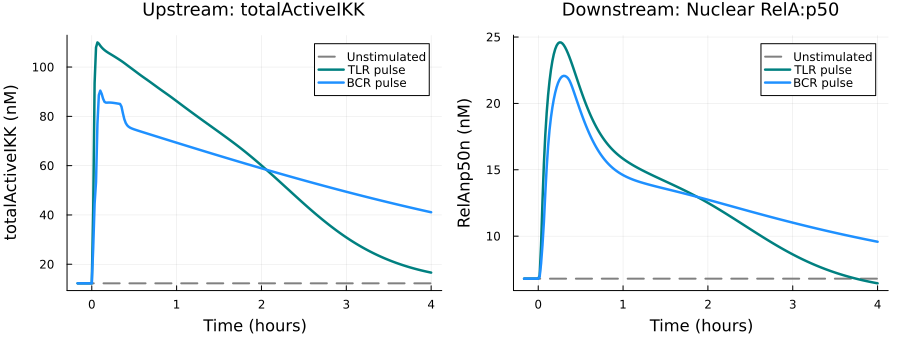

In [3]:
# Conserved upstream protein pools (from SiFTW/NFkBModel/Figure5/runSimulation.jl)
function make_tri_y0(syms)
    y0 = zeros(length(syms))
    inits = [
        ("MYD88", 0.1), ("TRIF", 0.1), ("TRAF6", 0.1), ("IKKK_off", 0.1),
        ("IKK_off", 0.1), ("TBK1", 0.1), ("IRF3", 0.1), ("CD14", 0.08),
        ("cbswitch", 0.0), ("C", 1.0), ("B", 1.0), ("M", 1.0),
        ("TAK1", 1.0), ("IKK", 1.0), ("totalinactiveIKK", 200.0),
    ]
    for (name, val) in inits
        y0[findfirst(x -> x == name, syms)] = val
    end
    return y0
end

# Exact Figure 5 input functions
bcrSS     = t -> 0.0
bcrSSHigh = t -> 0.05   # Chronic basal BCR signalling (e.g. CD79B mutation)
bcrTC     = t -> (t >= 10.0 && t < 30.0) ? 1.0 : 0.0
tlrSS     = t -> 0.0
tlrTC     = t -> (t >= 10.0 && t < 30.0) ? 100.0 : 0.0
nikSS     = t -> 1.0

stiff_alg = FBDF(autodiff=AutoFiniteDiff())
maxTimeSS = 100000.0
maxTimeTC = 4.0 * 60.0 + 10.0   # 10 min pre-stimulus + 4 h post-stimulus

function run_single_tri_cell(; bcr_ss=bcrSS, bcr_tc=bcrSS, tlr_ss=tlrSS, tlr_tc=tlrSS,
                             param_scales=Dict{String,Float64}())
    p = copy(paramVals)
    for (pname, factor) in param_scales
        idx = findfirst(x -> x == pname, parameterNameList)
        isnothing(idx) && error("Parameter \"$pname\" not found in parameterNameList!")
        p[idx] = p[idx] * factor
    end

    # Phase 1: Steady State
    p[BCRIndex] = bcr_ss
    p[TLRIndex] = tlr_ss
    p[NIKIndex] = nikSS
    sol_ss = solve(ODEProblem(ODEFunction(triModelFig5), make_tri_y0(syms), (0.0, maxTimeSS), p),
                   stiff_alg; saveat=1000.0)
    y0_tc = max.(collect(Float64, sol_ss.u[end]), 0.0)

    # Phase 2: Dynamic Time Course
    p[BCRIndex] = bcr_tc
    p[TLRIndex] = tlr_tc
    sol_tc = solve(ODEProblem(ODEFunction(triModelFig5), y0_tc, (0.0, maxTimeTC), p),
                   stiff_alg; tstops=[10.0, 10.5, 12.0, 30.0], abstol=1e-5, reltol=1e-3, saveat=1.0)
    return sol_tc
end

sol_rest = run_single_tri_cell()
sol_tlr  = run_single_tri_cell(tlr_tc=tlrTC)
sol_bcr  = run_single_tri_cell(bcr_tc=bcrTC)

# Shift time axis so t = 0 h corresponds to pulse onset (10 min into the solver)
t_hrs = (sol_rest.t .- 10.0) ./ 60.0

p1 = plot(t_hrs, sol_rest[idx_IKK, :], label="Unstimulated", lw=2.0, ls=:dash, color=:gray,
          title="Upstream: totalActiveIKK", titlefontsize=12,
          xlabel="Time (hours)", ylabel="totalActiveIKK (nM)")
plot!(p1, t_hrs, sol_tlr[idx_IKK, :], label="TLR pulse", lw=2.5, color=:teal)
plot!(p1, t_hrs, sol_bcr[idx_IKK, :], label="BCR pulse", lw=2.5, color=:dodgerblue)

p2 = plot(t_hrs, sol_rest[idx_RelA, :], label="Unstimulated", lw=2.0, ls=:dash, color=:gray,
          title="Downstream: Nuclear RelA:p50", titlefontsize=12,
          xlabel="Time (hours)", ylabel="RelAnp50n (nM)")
plot!(p2, t_hrs, sol_tlr[idx_RelA, :], label="TLR pulse", lw=2.5, color=:teal)
plot!(p2, t_hrs, sol_bcr[idx_RelA, :], label="BCR pulse", lw=2.5, color=:dodgerblue)

plot(p1, p2, layout=(1, 2), size=(900, 350))

In this combined model, we no longer hand-draw an IKK curve: stimulating **TLR** or **BCR** activates upstream adapters, generates a dynamic `totalActiveIKK` wave inside the `linking` module, and drives nuclear **`RelAnp50n`** downstream.

---

## Interactive Exercises

### Exercise 1: Search Module-Tagged Parameters

When combining modules, every parameter name carries its module tag (`-BCR`, `-TLR`, `-NFkB`, or `-linking`).

**Your task:** Edit the cell below to list all parameters in `parameterNameList` that belong to the **`-TLR`** module and contain `"MYD88"` (or try searching for `"Tp0"` in `-BCR`, or `"IKK"` in `-linking`).

In [4]:
# Exercise 1: Change the search terms to inspect parameters from different modules!
module_suffix = "-NFkB"
keyword       = "RelA"

matches = filter(p -> endswith(p, module_suffix) && occursin(keyword, p), parameterNameList)
println("Found ", length(matches), " matching parameters:")
for m in matches
    idx = findfirst(x -> x == m, parameterNameList)
    println("  [", idx, "] ", m, " = ", paramVals[idx])
end

Found 42 matching parameters:
  [188] k1_RelAp50binding-NFkB = 0.0019


  [189] k1_RelAnp50nbinding-NFkB = 0.0019
  [190] k1_RelAp52binding-NFkB = 0.00096
  [191] k1_RelAnp52nbinding-NFkB = 0.00096
  [206] k1_RelAp50unbinding-NFkB = 0.019
  [207] k1_RelAnp50nunbinding-NFkB = 0.0019
  [208] k1_RelAp52unbinding-NFkB = 0.948
  [209] k1_RelAnp52nunbinding-NFkB = 0.0019
  [228] k1_IkBaRelA50Ass-NFkB = 0.003
  [229] k1_IkBbRelA50Ass-NFkB = 0.000213
  [230] k1_IkBeRelA50Ass-NFkB = 0.0013
  [231] k1_IkBdRelA50Ass-NFkB = 0.0006
  [252] k1_IkBaRelA52Ass-NFkB = 0.003
  [253] k1_IkBbRelA52Ass-NFkB = 0.000213
  [254] k1_IkBeRelA52Ass-NFkB = 0.0013
  [255] k1_IkBdRelA52Ass-NFkB = 0.0006
  [256] k1_IkBaRelA50Diss-NFkB = 0.0006
  [257] k1_IkBbRelA50Diss-NFkB = 0.0169
  [258] k1_IkBeRelA50Diss-NFkB = 0.006
  [259] k1_IkBdRelA50Diss-NFkB = 0.00084
  [280] k1_IkBaRelA52Diss-NFkB = 0.0006
  [281] k1_IkBbRelA52Diss-NFkB = 0.0169
  [282] k1_IkBeRelA52Diss-NFkB = 0.006
  [283] k1_IkBdRelA52Diss-NFkB = 0.00084
  [284] k1_RelAp50IkBanucImport-NFkB = 0.276
  [285] k1_RelAp50IkBbnu

````{admonition} Hint
:class: dropdown tip

Set `module_suffix = "-TLR"` and `keyword = "MYD88"` (and notice `k1_MYD88SELFACTIVATION-TLR`, which represents spontaneous MYD88 signalling as in the MYD88 L265P/L275P lymphoma mutation!).
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
module_suffix = "-TLR"
keyword       = "MYD88"

matches = filter(p -> endswith(p, module_suffix) && occursin(keyword, p), parameterNameList)
println("Found ", length(matches), " matching parameters:")
for m in matches
    idx = findfirst(x -> x == m, parameterNameList)
    println("  [", idx, "] ", m, " = ", paramVals[idx])
end
```
````

### Exercise 2: Preview a Chronic BCR (`CD79B`) Mutation Under TLR Stimulation

In several aggressive B-cell lymphomas, a `CD79B` mutation causes **chronic basal BCR signalling** (`bcrSSHigh = t -> 0.05`) even before any external stimulus arrives.

**Your task:** Edit the cell below to simulate a cell with chronic basal BCR signalling (`bcr_ss=bcrSSHigh, bcr_tc=bcrSSHigh, tlr_tc=tlrTC`) and compare BOTH its **absolute nuclear `RelAnp50n` (nM)** and its **fold change (`RelAnp50n(t) / RelAnp50n(0)`)** against the normal wild-type cell (`sol_tlr`).

Wild-type steady state:    6.8 nM  | Peak fold change: 3.62×
Your condition steady state: 6.8 nM  | Peak fold change: 3.62×


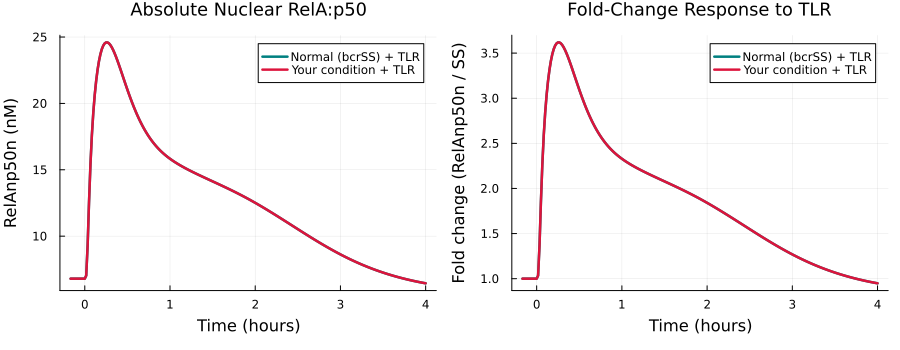

In [5]:
# Exercise 2: Change bcr_ss and bcr_tc below from bcrSS to bcrSSHigh to add chronic BCR signalling!
sol_cd79 = run_single_tri_cell(bcr_ss=bcrSS, bcr_tc=bcrSS, tlr_tc=tlrTC)

wt_rela   = sol_tlr[idx_RelA, :]
mut_rela  = sol_cd79[idx_RelA, :]

println("Wild-type steady state:    ", round(wt_rela[1], digits=2), " nM  | Peak fold change: ", round(maximum(wt_rela) / wt_rela[1], digits=2), "×")
println("Your condition steady state: ", round(mut_rela[1], digits=2), " nM  | Peak fold change: ", round(maximum(mut_rela) / mut_rela[1], digits=2), "×")

p_abs = plot(t_hrs, wt_rela,  label="Normal (bcrSS) + TLR", lw=2.5, color=:teal,
             title="Absolute Nuclear RelA:p50", titlefontsize=12,
             xlabel="Time (hours)", ylabel="RelAnp50n (nM)")
plot!(p_abs, t_hrs, mut_rela, label="Your condition + TLR", lw=2.5, color=:crimson)

p_fc = plot(t_hrs, wt_rela ./ wt_rela[1],   label="Normal (bcrSS) + TLR", lw=2.5, color=:teal,
            title="Fold-Change Response to TLR", titlefontsize=12,
            xlabel="Time (hours)", ylabel="Fold change (RelAnp50n / SS)")
plot!(p_fc, t_hrs, mut_rela ./ mut_rela[1], label="Your condition + TLR", lw=2.5, color=:crimson)

plot(p_abs, p_fc, layout=(1, 2), size=(900, 350))

````{admonition} Hint
:class: dropdown tip

Change the first line to:
```julia
sol_cd79 = run_single_tri_cell(bcr_ss=bcrSSHigh, bcr_tc=bcrSSHigh, tlr_tc=tlrTC)
```
Watch what happens in the left panel vs the right panel: resting `RelAnp50n` goes **up**, while the **fold-change spike** to TLR stimulation drops sharply!
````

````{admonition} Reveal Solution
:class: dropdown note

```julia
sol_cd79 = run_single_tri_cell(bcr_ss=bcrSSHigh, bcr_tc=bcrSSHigh, tlr_tc=tlrTC)

wt_rela  = sol_tlr[idx_RelA, :]
mut_rela = sol_cd79[idx_RelA, :]

println("Wild-type steady state:     ", round(wt_rela[1], digits=2), " nM  | Peak fold change: ", round(maximum(wt_rela) / wt_rela[1], digits=2), "×")
println("CD79B mutant steady state:  ", round(mut_rela[1], digits=2), " nM  | Peak fold change: ", round(maximum(mut_rela) / mut_rela[1], digits=2), "×")

p_abs = plot(t_hrs, wt_rela,  label="Normal (bcrSS) + TLR", lw=2.5, color=:teal,
             title="Absolute Nuclear RelA:p50", titlefontsize=12,
             xlabel="Time (hours)", ylabel="RelAnp50n (nM)")
plot!(p_abs, t_hrs, mut_rela, label="Chronic BCR (CD79B) + TLR", lw=2.5, color=:crimson)

p_fc = plot(t_hrs, wt_rela ./ wt_rela[1],   label="Normal (bcrSS) + TLR", lw=2.5, color=:teal,
            title="Fold-Change Response to TLR", titlefontsize=12,
            xlabel="Time (hours)", ylabel="Fold change (RelAnp50n / SS)")
plot!(p_fc, t_hrs, mut_rela ./ mut_rela[1], label="Chronic BCR (CD79B) + TLR", lw=2.5, color=:crimson)

plot(p_abs, p_fc, layout=(1, 2), size=(900, 350))
```

Notice that chronic BCR activity raises resting nuclear `RelAnp50n` and induces negative feedback at steady state — leaving much less headroom for an acute TLR signal to increase nuclear RelA:p50 further. This exact mechanism is central to Figure 5 of Jayawant *et al.*!
````

Now head to **[2. Recreating Figure 5 of Jayawant *et al.*](./02-recreating-figure-5.ipynb)** to simulate heterogeneous cell populations of all four DLBCL cell lines and reproduce the published figure!